# Great Britain Electricity Demand Forecasting

This notebook explores hourly electricity demand in Great Britain, prepares the time series, and compares a seasonal naive baseline with ARIMA, SARIMA and an LSTM model.

**Evaluation approach:** the final model comparison uses the same first 168 hours (seven days) of the chronological test set. Statistical models are updated with each newly observed demand value, and the LSTM uses the previous 24 observed hours as input. The full-test forecasts shown earlier are separate fixed-origin experiments and should not be compared directly with the seven-day results.

## 1. Imports and data loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error

df = pd.read_csv("../data/time_series_60min_singleindex.csv")
df.head()

,utc_timestamp,cet_cest_timestamp,AT_load_actual_entsoe_transparency,AT_load_forecast_entsoe_transparency,AT_price_day_ahead,AT_solar_generation_actual,AT_wind_onshore_generation_actual,BE_load_actual_entsoe_transparency,BE_load_forecast_entsoe_transparency,BE_solar_generation_actual,...,SI_load_actual_entsoe_transparency,SI_load_forecast_entsoe_transparency,SI_solar_generation_actual,SI_wind_onshore_generation_actual,SK_load_actual_entsoe_transparency,SK_load_forecast_entsoe_transparency,SK_solar_generation_actual,SK_wind_onshore_generation_actual,UA_load_actual_entsoe_transparency,UA_load_forecast_entsoe_transparency
0,2014-12-31T23:00:00Z,2015-01-01T00:00:00+0100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2015-01-01T00:00:00Z,2015-01-01T01:00:00+0100,5946.0,6701.0,35.0,NaN,69.0,9484.0,9897.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2015-01-01T01:00:00Z,2015-01-01T02:00:00+0100,5726.0,6593.0,45.0,NaN,64.0,9152.0,9521.0,NaN,...,1045.47,816.0,NaN,1.17,2728.0,2860.0,3.8,NaN,NaN,NaN
3,2015-01-01T02:00:00Z,2015-01-01T03:00:00+0100,5347.0,6482.0,41.0,NaN,65.0,8799.0,9135.0,NaN,...,1004.79,805.0,NaN,1.04,2626.0,2810.0,3.8,NaN,NaN,NaN
4,2015-01-01T03:00:00Z,2015-01-01T04:00:00+0100,5249.0,6454.0,38.0,NaN,64.0,8567.0,8909.0,NaN,...,983.79,803.0,NaN,1.61,2618.0,2780.0,3.8,NaN,NaN,NaN


In [2]:
df.shape

(50401, 300)

In [3]:
df.columns.tolist()

['utc_timestamp',
 'cet_cest_timestamp',
 'AT_load_actual_entsoe_transparency',
 'AT_load_forecast_entsoe_transparency',
 'AT_price_day_ahead',
 'AT_solar_generation_actual',
 'AT_wind_onshore_generation_actual',
 'BE_load_actual_entsoe_transparency',
 'BE_load_forecast_entsoe_transparency',
 'BE_solar_generation_actual',
 'BE_wind_generation_actual',
 'BE_wind_offshore_generation_actual',
 'BE_wind_onshore_generation_actual',
 'BG_load_actual_entsoe_transparency',
 'BG_load_forecast_entsoe_transparency',
 'BG_solar_generation_actual',
 'BG_wind_onshore_generation_actual',
 'CH_load_actual_entsoe_transparency',
 'CH_load_forecast_entsoe_transparency',
 'CH_solar_capacity',
 'CH_solar_generation_actual',
 'CH_wind_onshore_capacity',
 'CH_wind_onshore_generation_actual',
 'CY_load_actual_entsoe_transparency',
 'CY_load_forecast_entsoe_transparency',
 'CY_wind_onshore_generation_actual',
 'CZ_load_actual_entsoe_transparency',
 'CZ_load_forecast_entsoe_transparency',
 'CZ_solar_generation_

In [4]:
df[['utc_timestamp', 'cet_cest_timestamp']].head()

,utc_timestamp,cet_cest_timestamp
0,2014-12-31T23:00:00Z,2015-01-01T00:00:00+0100
1,2015-01-01T00:00:00Z,2015-01-01T01:00:00+0100
2,2015-01-01T01:00:00Z,2015-01-01T02:00:00+0100
3,2015-01-01T02:00:00Z,2015-01-01T03:00:00+0100
4,2015-01-01T03:00:00Z,2015-01-01T04:00:00+0100


In [5]:
df.isnull().sum().sort_values(ascending=False).head(20)

HR_solar_generation_actual                 50391
HR_wind_onshore_generation_actual          50379
PT_wind_offshore_generation_actual         47509
PT_wind_generation_actual                  47509
PL_solar_generation_actual                 46237
HU_solar_generation_actual                 41436
SK_wind_onshore_generation_actual          40722
NO_5_wind_onshore_generation_actual        40132
NO_1_wind_onshore_generation_actual        35815
DE_LU_load_forecast_entsoe_transparency    33745
IE_sem_price_day_ahead                     32886
DE_LU_load_actual_entsoe_transparency      32877
DE_LU_solar_generation_actual              32862
DE_LU_price_day_ahead                      32861
DE_LU_wind_onshore_generation_actual       32855
DE_LU_wind_offshore_generation_actual      32855
DE_LU_wind_generation_actual               32855
ME_wind_onshore_generation_actual          29941
CY_load_forecast_entsoe_transparency       29048
UA_load_forecast_entsoe_transparency       24988
dtype: int64

## 2. Select Great Britain demand and explore the raw series

In [6]:
uk_df = df[['utc_timestamp', 'GB_GBN_load_actual_entsoe_transparency']].copy()

In [7]:
uk_df.head()

,utc_timestamp,GB_GBN_load_actual_entsoe_transparency
0,2014-12-31T23:00:00Z,NaN
1,2015-01-01T00:00:00Z,26758.0
2,2015-01-01T01:00:00Z,27166.0
3,2015-01-01T02:00:00Z,24472.0
4,2015-01-01T03:00:00Z,23003.0


In [8]:
uk_df = uk_df.rename(columns={
    'utc_timestamp': 'timestamp',
    'GB_GBN_load_actual_entsoe_transparency': 'demand'
})

In [9]:
uk_df.head()

,timestamp,demand
0,2014-12-31T23:00:00Z,NaN
1,2015-01-01T00:00:00Z,26758.0
2,2015-01-01T01:00:00Z,27166.0
3,2015-01-01T02:00:00Z,24472.0
4,2015-01-01T03:00:00Z,23003.0


In [10]:
uk_df.info()
uk_df['demand'].isna().sum()
uk_df['demand'].describe()

<class 'pandas.DataFrame'>
RangeIndex: 50401 entries, 0 to 50400
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   timestamp  50401 non-null  str    
 1   demand     50394 non-null  float64
dtypes: float64(1), str(1)
memory usage: 787.6 KB


count    50394.000000
mean     34920.874152
std       7888.618203
min        511.000000
25%      28860.250000
50%      35306.500000
75%      40774.000000
max      57388.000000
Name: demand, dtype: float64

In [11]:
uk_df['timestamp'] = pd.to_datetime(uk_df['timestamp'], utc=True)
uk_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50401 entries, 0 to 50400
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype              
---  ------     --------------  -----              
 0   timestamp  50401 non-null  datetime64[us, UTC]
 1   demand     50394 non-null  float64            
dtypes: datetime64[us, UTC](1), float64(1)
memory usage: 787.6 KB


In [12]:
uk_df['timestamp'].min(), uk_df['timestamp'].max()

(Timestamp('2014-12-31 23:00:00+0000', tz='UTC'),
 Timestamp('2020-09-30 23:00:00+0000', tz='UTC'))

In [13]:
uk_df[uk_df['demand'].isna()]

,timestamp,demand
0,2014-12-31 23:00:00+00:00,NaN
2090,2015-03-29 01:00:00+00:00,NaN
2091,2015-03-29 02:00:00+00:00,NaN
2092,2015-03-29 03:00:00+00:00,NaN
19562,2017-03-26 01:00:00+00:00,NaN
19563,2017-03-26 02:00:00+00:00,NaN
19564,2017-03-26 03:00:00+00:00,NaN


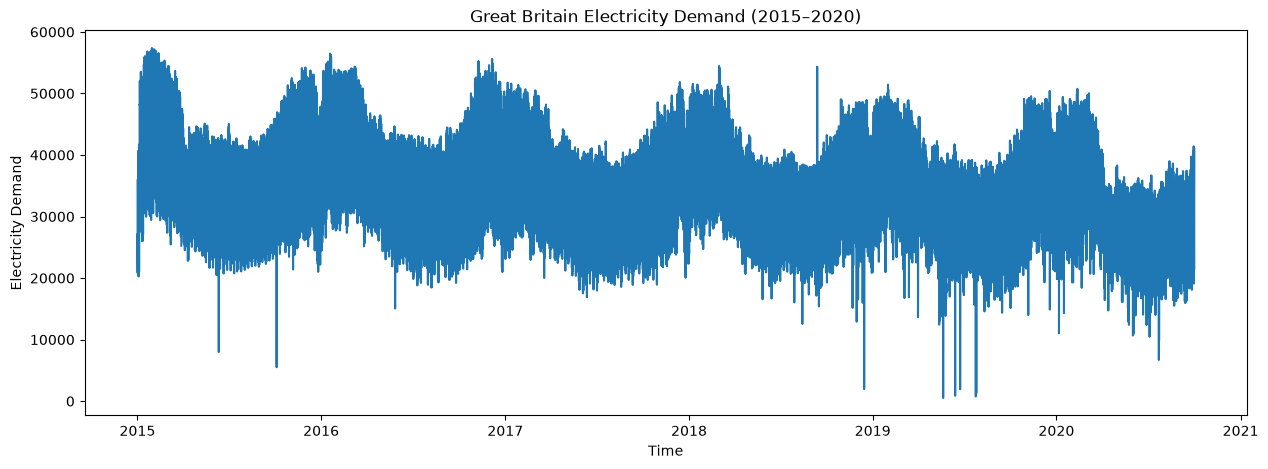

In [14]:
plt.figure(figsize=(15, 5))

plt.plot(uk_df['timestamp'], uk_df['demand'])

plt.xlabel('Time')
plt.ylabel('Electricity Demand')
plt.title('Great Britain Electricity Demand (2015–2020)')

plt.show()

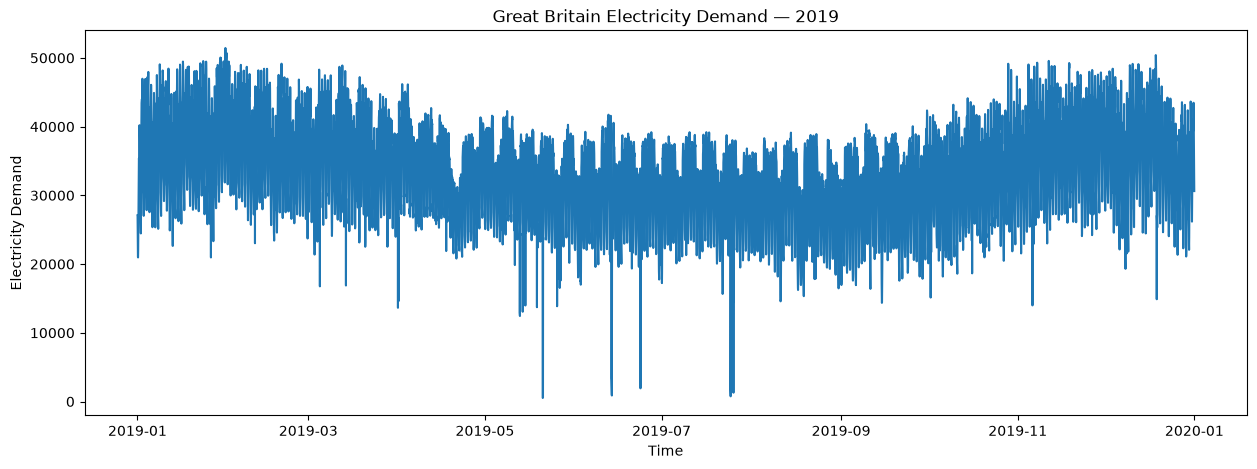

In [15]:
one_year = uk_df[
    (uk_df['timestamp'] >= '2019-01-01') &
    (uk_df['timestamp'] < '2020-01-01')
]

plt.figure(figsize=(15, 5))

plt.plot(one_year['timestamp'], one_year['demand'])

plt.xlabel('Time')
plt.ylabel('Electricity Demand')
plt.title('Great Britain Electricity Demand — 2019')

plt.show()

In [16]:
uk_df.nsmallest(20, 'demand')[['timestamp', 'demand']]

,timestamp,demand
38424,2019-05-20 23:00:00+00:00,511.0
38425,2019-05-21 00:00:00+00:00,539.0
38426,2019-05-21 01:00:00+00:00,575.0
39981,2019-07-24 20:00:00+00:00,757.0
39982,2019-07-24 21:00:00+00:00,852.0
38997,2019-06-13 20:00:00+00:00,874.0
39980,2019-07-24 19:00:00+00:00,926.0
38996,2019-06-13 19:00:00+00:00,1029.0
40005,2019-07-25 20:00:00+00:00,1282.0
40004,2019-07-25 19:00:00+00:00,1476.0


In [17]:
uk_df[
    (uk_df['timestamp'] >= '2019-06-13 12:00:00+00:00') &
    (uk_df['timestamp'] <= '2019-06-14 06:00:00+00:00')
][['timestamp', 'demand']]

,timestamp,demand
38989,2019-06-13 12:00:00+00:00,22639.0
38990,2019-06-13 13:00:00+00:00,22258.0
38991,2019-06-13 14:00:00+00:00,21917.0
38992,2019-06-13 15:00:00+00:00,3378.0
38993,2019-06-13 16:00:00+00:00,3116.0
38994,2019-06-13 17:00:00+00:00,2289.0
38995,2019-06-13 18:00:00+00:00,1540.0
38996,2019-06-13 19:00:00+00:00,1029.0
38997,2019-06-13 20:00:00+00:00,874.0
38998,2019-06-13 21:00:00+00:00,15819.0


In [18]:
uk_df['demand'].describe()

count    50394.000000
mean     34920.874152
std       7888.618203
min        511.000000
25%      28860.250000
50%      35306.500000
75%      40774.000000
max      57388.000000
Name: demand, dtype: float64

In [19]:
uk_df[uk_df['demand'] < 10000].shape

(27, 2)

In [20]:
uk_df[uk_df['demand'] < 10000][['timestamp', 'demand']]

,timestamp,demand
3879,2015-06-11 14:00:00+00:00,7982.0
6638,2015-10-04 13:00:00+00:00,5512.0
34654,2018-12-14 21:00:00+00:00,1957.0
34655,2018-12-14 22:00:00+00:00,1984.0
34656,2018-12-14 23:00:00+00:00,2010.0
34657,2018-12-15 00:00:00+00:00,2038.0
34658,2018-12-15 01:00:00+00:00,2082.0
34659,2018-12-15 02:00:00+00:00,2128.0
38424,2019-05-20 23:00:00+00:00,511.0
38425,2019-05-21 00:00:00+00:00,539.0


In [21]:
uk_df[uk_df['demand'].isna()][['timestamp', 'demand']]

,timestamp,demand
0,2014-12-31 23:00:00+00:00,NaN
2090,2015-03-29 01:00:00+00:00,NaN
2091,2015-03-29 02:00:00+00:00,NaN
2092,2015-03-29 03:00:00+00:00,NaN
19562,2017-03-26 01:00:00+00:00,NaN
19563,2017-03-26 02:00:00+00:00,NaN
19564,2017-03-26 03:00:00+00:00,NaN


## 3. Clean the time series

The source series contains a small number of unusually low demand values. The original analysis flags values below 10,000 and replaces them using time based interpolation. 

In [34]:
clean_df = uk_df[['timestamp', 'demand']].copy()

clean_df['timestamp'] = pd.to_datetime(
    clean_df['timestamp'], utc=True
)

clean_df = clean_df.sort_values('timestamp').set_index('timestamp')

suspicious_mask = clean_df['demand'] < 10_000

print(
    "Observations below 10,000 before cleaning:",
    int(suspicious_mask.sum())
)

clean_df.loc[suspicious_mask, 'demand'] = np.nan

clean_df['demand'] = clean_df['demand'].interpolate(method='time')

# Fill any remaining missing value at the beginning or end
clean_df['demand'] = clean_df['demand'].bfill().ffill()

print("Missing demand values after cleaning:", int(clean_df['demand'].isna().sum()))
print("Cleaned observations:", len(clean_df))
print("Time range:", clean_df.index.min(), "to", clean_df.index.max())

clean_df['demand'].describe()

Observations below 10,000 before cleaning: 27
Missing demand values after cleaning: 0
Cleaned observations: 50401
Time range: 2014-12-31 23:00:00+00:00 to 2020-09-30 23:00:00+00:00


count    50401.000000
mean     34931.345092
std       7858.358439
min      10449.000000
25%      28862.000000
50%      35306.000000
75%      40774.000000
max      57388.000000
Name: demand, dtype: float64

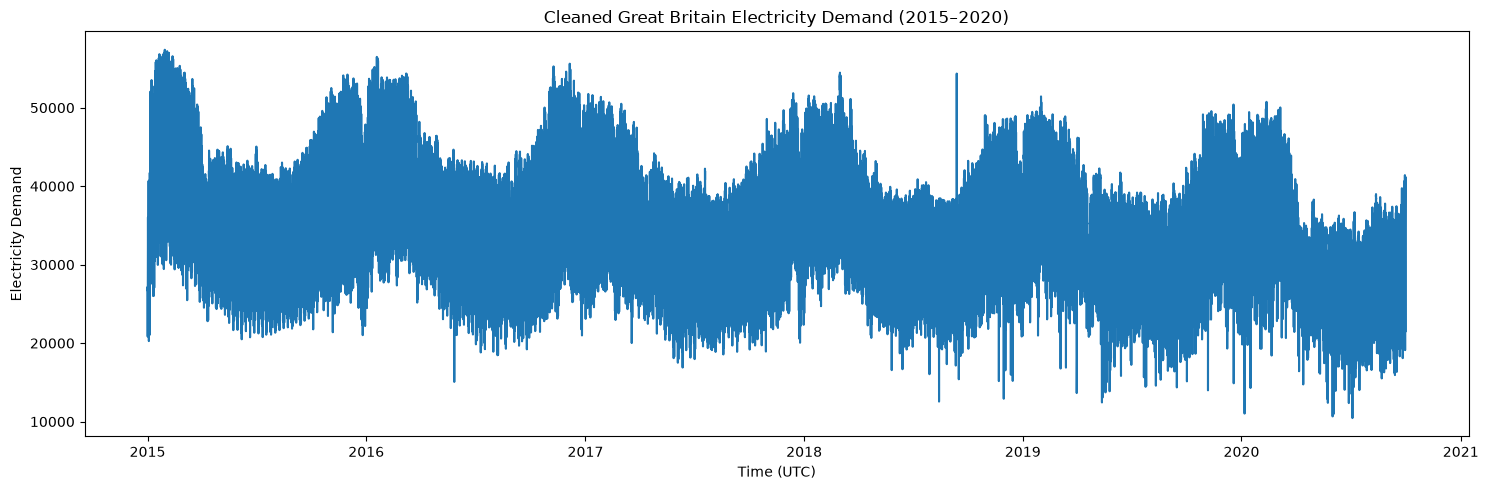

In [35]:
plt.figure(figsize=(15, 5))
plt.plot(clean_df.index, clean_df['demand'])
plt.xlabel('Time (UTC)')
plt.ylabel('Electricity Demand')
plt.title('Cleaned Great Britain Electricity Demand (2015–2020)')
plt.tight_layout()
plt.show()

## 4. Demand patterns in UK local time

In [36]:
clean_df['local_timestamp'] = clean_df.index.tz_convert('Europe/London')
clean_df['hour'] = clean_df['local_timestamp'].dt.hour
clean_df['day_of_week'] = clean_df['local_timestamp'].dt.dayofweek
clean_df['month'] = clean_df['local_timestamp'].dt.month

clean_df[['demand', 'local_timestamp', 'hour', 'day_of_week', 'month']].head()

,demand,local_timestamp,hour,day_of_week,month
timestamp,,,,,
2014-12-31 23:00:00+00:00,26758.0,2014-12-31 23:00:00+00:00,23,2,12
2015-01-01 00:00:00+00:00,26758.0,2015-01-01 00:00:00+00:00,0,3,1
2015-01-01 01:00:00+00:00,27166.0,2015-01-01 01:00:00+00:00,1,3,1
2015-01-01 02:00:00+00:00,24472.0,2015-01-01 02:00:00+00:00,2,3,1
2015-01-01 03:00:00+00:00,23003.0,2015-01-01 03:00:00+00:00,3,3,1


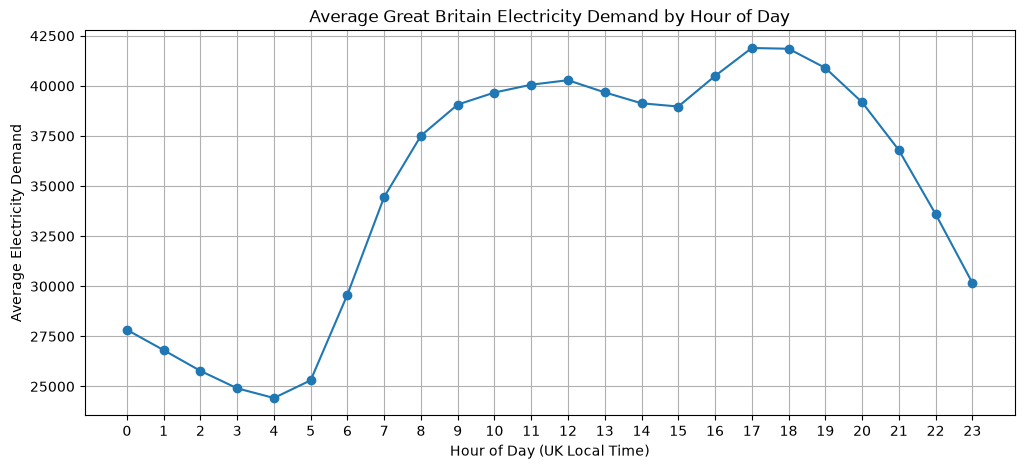

In [37]:
hourly_profile = clean_df.groupby('hour')['demand'].mean()

plt.figure(figsize=(12, 5))

plt.plot(hourly_profile.index, hourly_profile.values, marker='o')

plt.xlabel('Hour of Day (UK Local Time)')
plt.ylabel('Average Electricity Demand')
plt.title('Average Great Britain Electricity Demand by Hour of Day')

plt.xticks(range(24))
plt.grid(True)
plt.show()

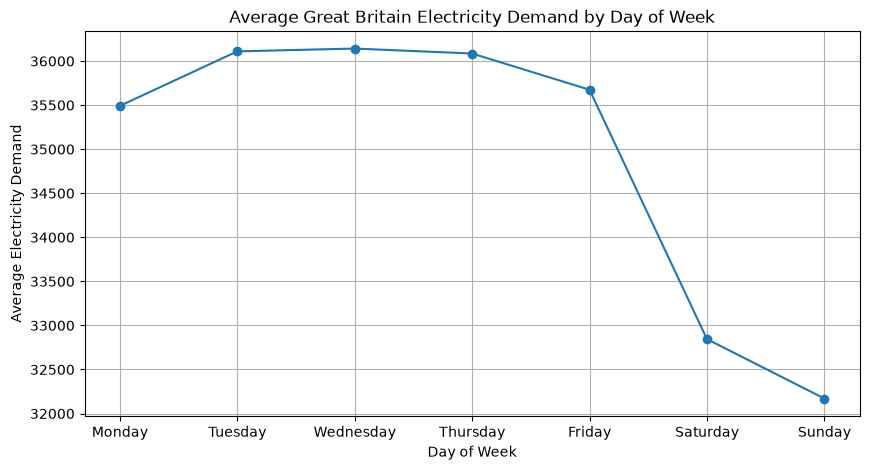

In [38]:
daily_profile = clean_df.groupby('day_of_week')['demand'].mean()

plt.figure(figsize=(10, 5))

plt.plot(daily_profile.index, daily_profile.values, marker='o')

plt.xlabel('Day of Week')
plt.ylabel('Average Electricity Demand')
plt.title('Average Great Britain Electricity Demand by Day of Week')

plt.xticks(
    range(7),
    ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
)

plt.grid(True)
plt.show()

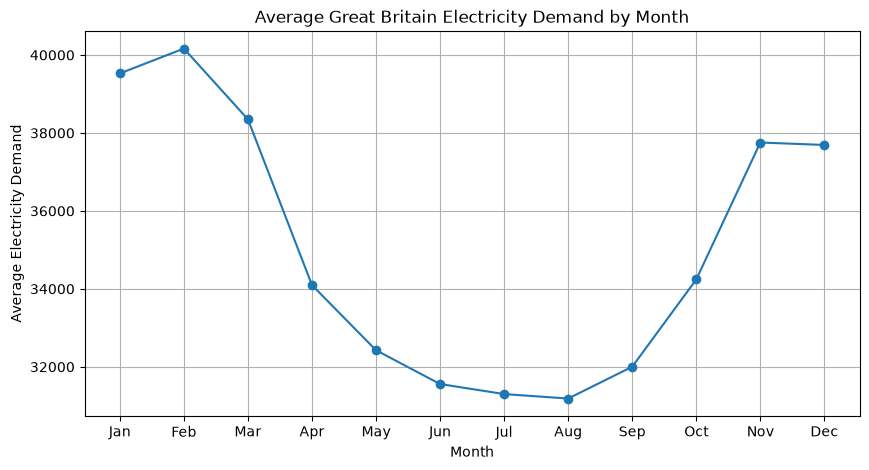

In [39]:
monthly_profile = clean_df.groupby('month')['demand'].mean()

plt.figure(figsize=(10, 5))

plt.plot(monthly_profile.index, monthly_profile.values, marker='o')

plt.xlabel('Month')
plt.ylabel('Average Electricity Demand')
plt.title('Average Great Britain Electricity Demand by Month')

plt.xticks(
    range(1, 13),
    ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
     'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
)

plt.grid(True)
plt.show()

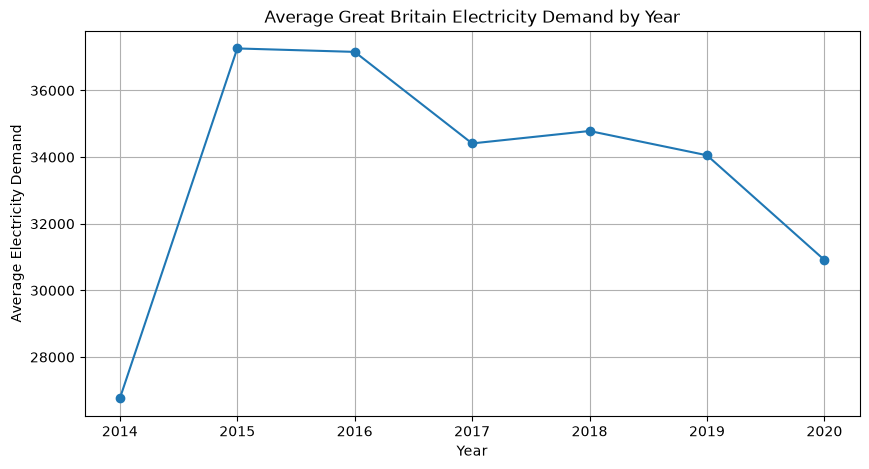

In [40]:
yearly_profile = clean_df.groupby(clean_df.index.year)['demand'].mean()

plt.figure(figsize=(10, 5))
plt.plot(yearly_profile.index, yearly_profile.values, marker='o')
plt.xlabel('Year')
plt.ylabel('Average Electricity Demand')
plt.title('Average Great Britain Electricity Demand by Year')
plt.xticks(yearly_profile.index)
plt.grid(True)
plt.show()

## 5. Forecasting dataset


In [41]:
forecast_df = clean_df[['demand']].copy()

split_index = int(len(forecast_df) * 0.8)
train = forecast_df.iloc[:split_index].copy()
test = forecast_df.iloc[split_index:].copy()

print("Training period:", train.index.min(), "to", train.index.max())
print("Test period:", test.index.min(), "to", test.index.max())
print("Training observations:", len(train))
print("Test observations:", len(test))

Training period: 2014-12-31 23:00:00+00:00 to 2019-08-07 22:00:00+00:00
Test period: 2019-08-07 23:00:00+00:00 to 2020-09-30 23:00:00+00:00
Training observations: 40320
Test observations: 10081


## 6. Baseline: previous-day seasonal naive

The full test baseline predicts each hour using demand from 24 hours earlier. This is a rolling seasonal naive forecast because later predictions can use observed values from the test period. The full test metrics below are reported separately from the final seven day model comparison.

In [42]:
baseline_test = forecast_df['demand'].shift(24).loc[test.index]
mae_baseline = mean_absolute_error(test['demand'], baseline_test)
rmse_baseline = np.sqrt(mean_squared_error(test['demand'], baseline_test))

print(f"Seasonal-naive full-test MAE: {mae_baseline:.2f}")
print(f"Seasonal-naive full-test RMSE: {rmse_baseline:.2f}")

Seasonal-naive full-test MAE: 2124.54
Seasonal-naive full-test RMSE: 3057.65


## 7. Time-series 

In [43]:
import numpy as np

print("Training rows:", len(train))
print("Missing values:", train['demand'].isna().sum())
print("Infinite values:", np.isinf(train['demand']).sum())
print("Data type:", train['demand'].dtype)

Training rows: 40320
Missing values: 0
Infinite values: 0
Data type: float64


In [44]:
train.loc[train['demand'].isna()]

,demand
timestamp,


In [45]:
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(train['demand'])

print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])

ADF Statistic: -10.98764055827493
p-value: 7.191860895639168e-20


/var/folders/4g/tpxyrqmj4j7c0lqgqs1wn6d40000gn/T/ipykernel_14993/2851197973.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(train['demand'])


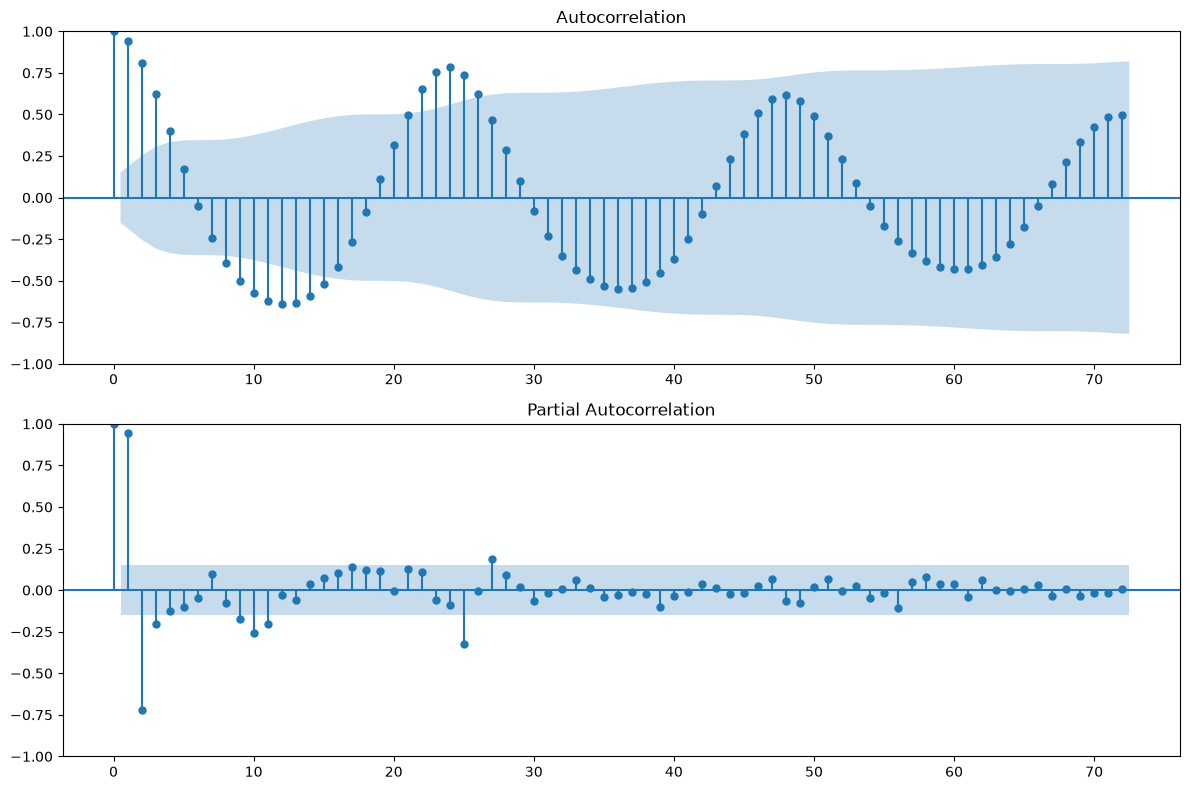

In [46]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

# Use a manageable recent portion for the diagnostic plots
train_sample = train['demand'].iloc[-7*24:]

fig, ax = plt.subplots(2, 1, figsize=(12, 8))

plot_acf(train_sample, lags=72, ax=ax[0])
plot_pacf(train_sample, lags=72, ax=ax[1])

plt.tight_layout()
plt.show()

## 8. ARIMA model

In [47]:
from statsmodels.tsa.arima.model import ARIMA

arima_orders = [
    (1, 0, 0),
    (2, 0, 0),
    (1, 0, 1),
    (2, 0, 1),
    (1, 0, 2),
    (2, 0, 2)
]

results = []

for order in arima_orders:
    model = ARIMA(train['demand'], order=order)
    fitted = model.fit()
    
    results.append({
        'ARIMA': order,
        'AIC': fitted.aic,
        'BIC': fitted.bic
    })

import pandas as pd

arima_results = pd.DataFrame(results)
arima_results.sort_values('AIC')

/opt/anaconda3/envs/power-forecast/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/power-forecast/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/power-forecast/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/power-forecast/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/power-forecast/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.p

,ARIMA,AIC,BIC
5,"(2, 0, 2)",720914.971630,720966.599247
3,"(2, 0, 1)",720936.339401,720979.362416
1,"(2, 0, 0)",721140.249056,721174.667468
4,"(1, 0, 2)",724566.549045,724609.572059
2,"(1, 0, 1)",729435.838850,729470.257262
0,"(1, 0, 0)",743616.852353,743642.666162


In [48]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

arima_model = ARIMA(train['demand'], order=(2, 0, 2))
arima_fitted = arima_model.fit()

arima_forecast = arima_fitted.forecast(steps=len(test))

arima_mae = mean_absolute_error(test['demand'], arima_forecast)
arima_rmse = np.sqrt(mean_squared_error(test['demand'], arima_forecast))

print("ARIMA(2,0,2) MAE:", arima_mae)
print("ARIMA(2,0,2) RMSE:", arima_rmse)

/opt/anaconda3/envs/power-forecast/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/power-forecast/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/power-forecast/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)


ARIMA(2,0,2) MAE: 7121.724072769197
ARIMA(2,0,2) RMSE: 8627.450773883575


The ARIMA full-test forecast above is a fixed-origin forecast. It is useful as a separate experiment, but its metrics are not used in the final seven-day rolling comparison.

## 9. SARIMA model

In [49]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
import pandas as pd

sarima_orders = [
    ((1, 0, 0), (1, 0, 0, 24)),
    ((1, 0, 1), (1, 0, 1, 24)),
    ((2, 0, 0), (1, 0, 0, 24)),
    ((2, 0, 1), (1, 0, 1, 24)),
    ((2, 0, 2), (1, 0, 1, 24))
]

sarima_results = []

for order, seasonal_order in sarima_orders:
    print(f"Fitting SARIMA{order}{seasonal_order}...")
    
    model = SARIMAX(
        train['demand'],
        order=order,
        seasonal_order=seasonal_order,
        enforce_stationarity=False,
        enforce_invertibility=False
    )
    
    fitted = model.fit(disp=False)
    
    sarima_results.append({
        'SARIMA': f"{order}{seasonal_order}",
        'AIC': fitted.aic,
        'BIC': fitted.bic
    })

sarima_results = pd.DataFrame(sarima_results)

sarima_results.sort_values('AIC')

Fitting SARIMA(1, 0, 0)(1, 0, 0, 24)...


/opt/anaconda3/envs/power-forecast/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/power-forecast/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)


Fitting SARIMA(1, 0, 1)(1, 0, 1, 24)...


/opt/anaconda3/envs/power-forecast/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/power-forecast/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)


Fitting SARIMA(2, 0, 0)(1, 0, 0, 24)...


...

Fitting SARIMA(2, 0, 1)(1, 0, 1, 24)...


/opt/anaconda3/envs/power-forecast/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/power-forecast/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)


Fitting SARIMA(2, 0, 2)(1, 0, 1, 24)...


/opt/anaconda3/envs/power-forecast/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/power-forecast/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/power-forecast/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,SARIMA,AIC,BIC
1,"(1, 0, 1)(1, 0, 1, 24)",685703.039148,685746.058937
4,"(2, 0, 2)(1, 0, 1, 24)",699693.271190,699753.498721
3,"(2, 0, 1)(1, 0, 1, 24)",699895.825197,699947.448944
0,"(1, 0, 0)(1, 0, 0, 24)",700949.157367,700974.969315
2,"(2, 0, 0)(1, 0, 0, 24)",706905.200315,706939.616146


In [50]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

sarima_model = SARIMAX(
    train['demand'],
    order=(1, 0, 1),
    seasonal_order=(1, 0, 1, 24),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fitted = sarima_model.fit(disp=False)

sarima_forecast = sarima_fitted.forecast(steps=len(test))

sarima_mae = mean_absolute_error(test['demand'], sarima_forecast)
sarima_rmse = np.sqrt(mean_squared_error(test['demand'], sarima_forecast))

print("SARIMA(1,0,1)(1,0,1,24) MAE:", sarima_mae)
print("SARIMA(1,0,1)(1,0,1,24) RMSE:", sarima_rmse)

/opt/anaconda3/envs/power-forecast/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/power-forecast/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)


SARIMA(1,0,1)(1,0,1,24) MAE: 6783.17810936158
SARIMA(1,0,1)(1,0,1,24) RMSE: 8100.151557179566


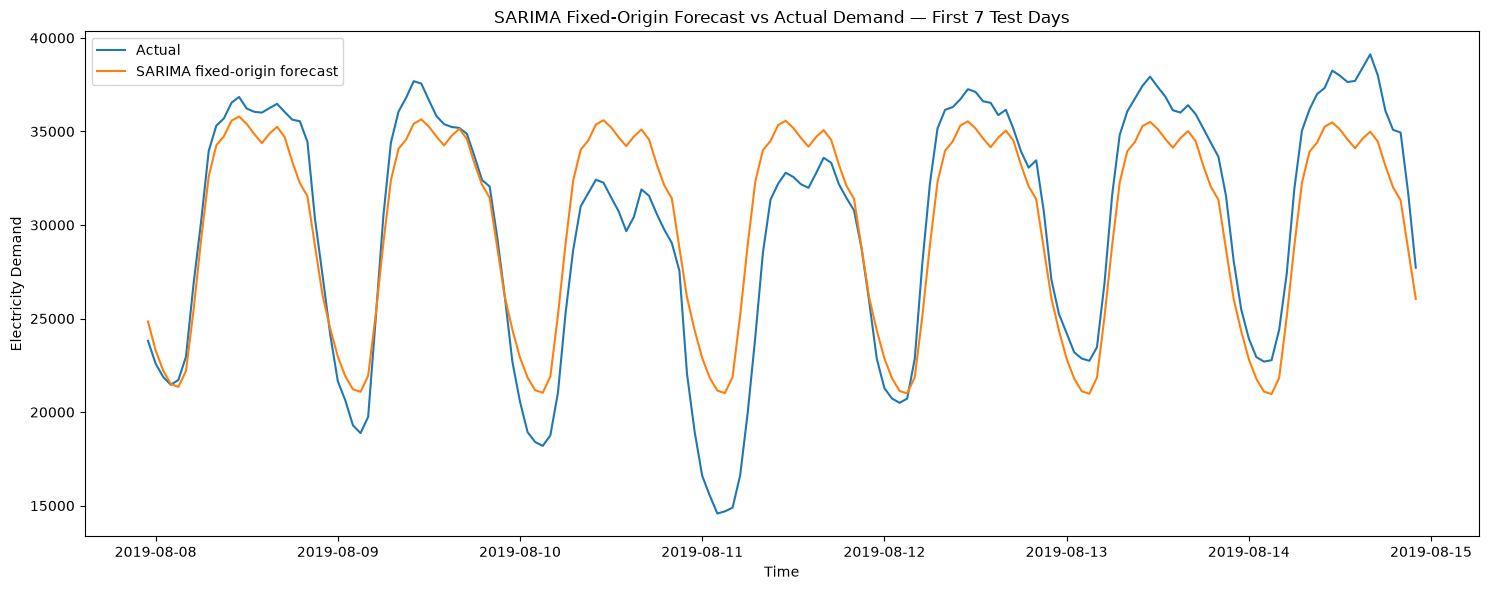

In [51]:
plt.figure(figsize=(15, 6))
plt.plot(test.index[:168], test['demand'].iloc[:168], label='Actual')
plt.plot(test.index[:168], sarima_forecast.iloc[:168], label='SARIMA fixed-origin forecast')
plt.title('SARIMA Fixed-Origin Forecast vs Actual Demand — First 7 Test Days')
plt.xlabel('Time')
plt.ylabel('Electricity Demand')
plt.legend()
plt.tight_layout()
plt.show()

## 10. LSTM model

The LSTM is trained on scaled training demand only. Test values are transformed with the same scaler, and each test sequence contains the previous 24 observed hours. The model produces one step ahead predictions across the test set; the seven day subset is used in the final comparison.

In [52]:
from sklearn.preprocessing import MinMaxScaler
import numpy as np
import torch

train_demand = train['demand'].values
test_demand = test['demand'].values

scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(
    train_demand.reshape(-1, 1)
)

test_scaled = scaler.transform(
    test_demand.reshape(-1, 1)
)

print("Training observations:", len(train_scaled))
print("Testing observations:", len(test_scaled))
print("Scaled training range:", train_scaled.min(), "to", train_scaled.max())
print("Scaled testing range:", test_scaled.min(), "to", test_scaled.max())

Training observations: 40320
Testing observations: 10081
Scaled training range: 0.0 to 1.0
Scaled testing range: -0.0442956305063629 to 0.8523404823351429


In [55]:
sequence_length = 24

def create_sequences(data, sequence_length):
    X = []
    y = []
    
    for i in range(sequence_length, len(data)):
        X.append(data[i-sequence_length:i])
        y.append(data[i])
    
    return np.array(X), np.array(y)


X_train, y_train = create_sequences(
    train_scaled,
    sequence_length
)

combined = np.concatenate([
    train_scaled[-sequence_length:],
    test_scaled
])

X_test, y_test = create_sequences(
    combined,
    sequence_length
)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (40296, 24, 1)
y_train shape: (40296, 1)
X_test shape: (10081, 24, 1)
y_test shape: (10081, 1)


In [56]:
from torch.utils.data import TensorDataset, DataLoader

# Convert NumPy arrays to PyTorch tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32)

# Create datasets
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("X_train tensor shape:", X_train_tensor.shape)
print("y_train tensor shape:", y_train_tensor.shape)
print("Number of training batches:", len(train_loader))
print("Number of test batches:", len(test_loader))

X_train tensor shape: torch.Size([40296, 24, 1])
y_train tensor shape: torch.Size([40296, 1])
Number of training batches: 630
Number of test batches: 158


In [57]:
import torch.nn as nn

class LSTMModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, num_layers=2):
        super().__init__()
        
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )
        
        self.fc = nn.Linear(hidden_size, 1)
    
    def forward(self, x):
        out, _ = self.lstm(x)
        
        out = out[:, -1, :]
        
        out = self.fc(out)
        
        return out


model = LSTMModel()

print(model)

LSTMModel(
  (lstm): LSTM(1, 64, num_layers=2, batch_first=True)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)


In [58]:
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: MSELoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [59]:
epochs = 10

train_losses = []

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        
        predictions = model(X_batch)
        
        loss = criterion(predictions, y_batch)
        
        loss.backward()
        
        optimizer.step()
        
        running_loss += loss.item()
    
    epoch_loss = running_loss / len(train_loader)
    train_losses.append(epoch_loss)
    
    print(
        f"Epoch {epoch + 1}/{epochs} - "
        f"Training Loss: {epoch_loss:.6f}"
    )

Epoch 1/10 - Training Loss: 0.008849
Epoch 2/10 - Training Loss: 0.001274
Epoch 3/10 - Training Loss: 0.000968
Epoch 4/10 - Training Loss: 0.000896
Epoch 5/10 - Training Loss: 0.000866
Epoch 6/10 - Training Loss: 0.000834
Epoch 7/10 - Training Loss: 0.000776
Epoch 8/10 - Training Loss: 0.000749
Epoch 9/10 - Training Loss: 0.000723
Epoch 10/10 - Training Loss: 0.000709


In [60]:
model.eval()

predictions = []

with torch.no_grad():
    for X_batch, _ in test_loader:
        batch_predictions = model(X_batch)
        predictions.append(batch_predictions.numpy())

lstm_predictions_scaled = np.concatenate(predictions)

print("Scaled prediction shape:", lstm_predictions_scaled.shape)

Scaled prediction shape: (10081, 1)


In [61]:
lstm_predictions = scaler.inverse_transform(
    lstm_predictions_scaled
)

lstm_actual = scaler.inverse_transform(
    y_test
)

lstm_mae = mean_absolute_error(
    lstm_actual,
    lstm_predictions
)

lstm_rmse = np.sqrt(
    mean_squared_error(
        lstm_actual,
        lstm_predictions
    )
)

print("LSTM MAE:", lstm_mae)
print("LSTM RMSE:", lstm_rmse)

LSTM MAE: 827.1940423197103
LSTM RMSE: 1466.439866825456


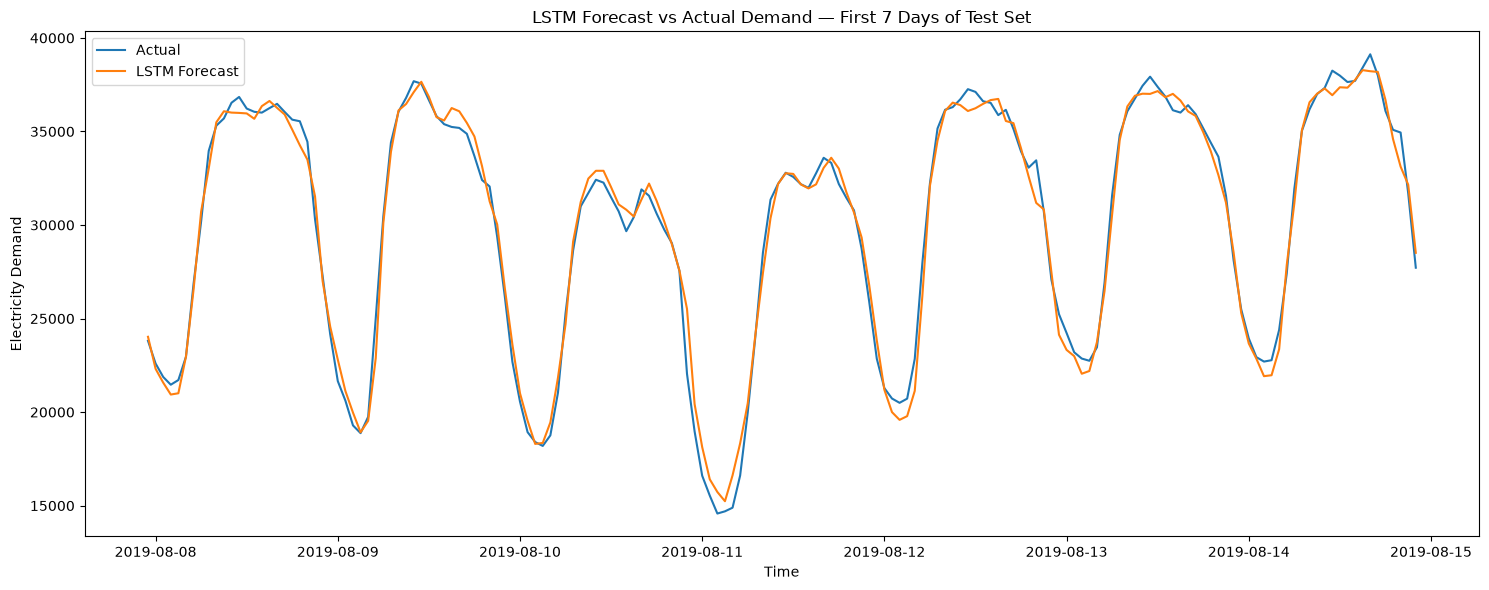

In [62]:
plt.figure(figsize=(15, 6))

plt.plot(
    test.index[:7*24],
    lstm_actual[:7*24],
    label='Actual'
)

plt.plot(
    test.index[:7*24],
    lstm_predictions[:7*24],
    label='LSTM Forecast'
)

plt.title('LSTM Forecast vs Actual Demand — First 7 Days of Test Set')
plt.xlabel('Time')
plt.ylabel('Electricity Demand')
plt.legend()

plt.tight_layout()
plt.show()

## 11. Standardised seven-day model comparison

All models are evaluated on the same first 168 observations in the test set. ARIMA and SARIMA are fitted on the training set, forecast one hour ahead, and then updated with the actual observation before forecasting the next hour. The seasonal-naive baseline also uses the observed demand from 24 hours earlier. LSTM predictions use the existing trained model and the same 168-hour evaluation window.

In [ ]:
evaluation_hours = 7 * 24
actual_7day = test['demand'].astype(float).iloc[:evaluation_hours].to_numpy()
test_subset = test['demand'].astype(float).iloc[:evaluation_hours]

arima_eval_fit = arima_fitted  
arima_7day_predictions = []
current_arima = arima_eval_fit
for actual in actual_7day:
    pred = current_arima.forecast(steps=1)
    arima_7day_predictions.append(float(np.asarray(pred).reshape(-1)[0]))
    current_arima = current_arima.extend(np.asarray([actual]))
arima_7day_predictions = np.asarray(arima_7day_predictions)

sarima_eval_fit = sarima_fitted  
sarima_7day_predictions = []
current_sarima = sarima_eval_fit
for actual in actual_7day:
    pred = current_sarima.forecast(steps=1)
    sarima_7day_predictions.append(float(np.asarray(pred).reshape(-1)[0]))
    current_sarima = current_sarima.extend(np.asarray([actual]))
sarima_7day_predictions = np.asarray(sarima_7day_predictions)

history = train['demand'].astype(float).tolist()
seasonal_naive_predictions = []
for actual in actual_7day:
    seasonal_naive_predictions.append(float(history[-24]))
    history.append(float(actual))
seasonal_naive_predictions = np.asarray(seasonal_naive_predictions)

lstm_predictions_7day = scaler.inverse_transform(
    lstm_predictions_scaled[:evaluation_hours].reshape(-1, 1)
).ravel()

assert all(len(x) == evaluation_hours for x in [
    actual_7day, arima_7day_predictions, sarima_7day_predictions,
    seasonal_naive_predictions, lstm_predictions_7day
])
assert all(np.isfinite(x).all() for x in [
    arima_7day_predictions, sarima_7day_predictions,
    seasonal_naive_predictions, lstm_predictions_7day
])

def regression_metrics(actual, predicted):
    return {
        'MAE': mean_absolute_error(actual, predicted),
        'RMSE': np.sqrt(mean_squared_error(actual, predicted))
    }

comparison_rows = []
for name, predictions in [
    ('Seasonal Naive (24-hour)', seasonal_naive_predictions),
    ('ARIMA(2,0,2)', arima_7day_predictions),
    ('SARIMA(1,0,1)(1,0,1,24)', sarima_7day_predictions),
    ('LSTM', lstm_predictions_7day),
]:
    metrics = regression_metrics(actual_7day, predictions)
    comparison_rows.append({'Model': name, **metrics})

results_comparison = pd.DataFrame(comparison_rows).sort_values('MAE').reset_index(drop=True)
print('Seven-Day Electricity Demand Forecast Comparison (168 observations)')
print(results_comparison.round(2).to_string(index=False))

Seven-Day Electricity Demand Forecast Comparison (168 observations)
                   Model     MAE    RMSE
 SARIMA(1,0,1)(1,0,1,24)  491.97  687.63
                    LSTM  576.55  760.20
            ARIMA(2,0,2)  928.99 1211.94
Seasonal Naive (24-hour) 2123.88 3028.35


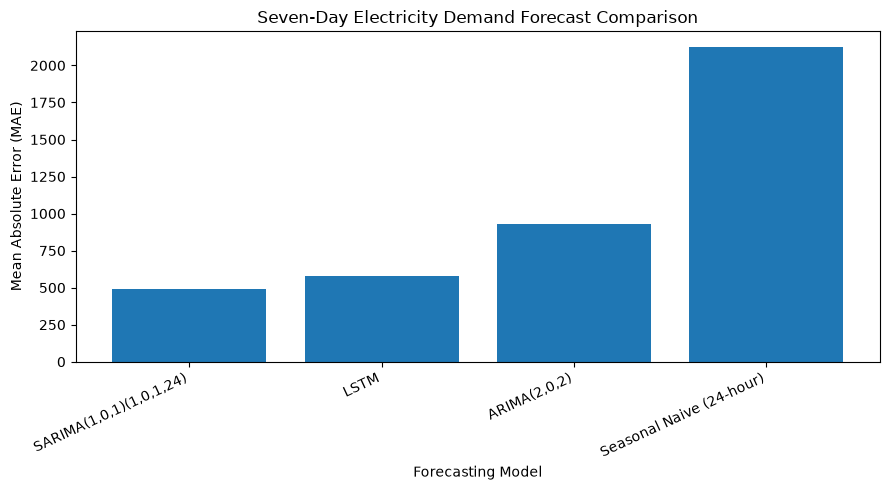

In [64]:
plt.figure(figsize=(9, 5))
plt.bar(results_comparison['Model'], results_comparison['MAE'])
plt.title('Seven-Day Electricity Demand Forecast Comparison')
plt.xlabel('Forecasting Model')
plt.ylabel('Mean Absolute Error (MAE)')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

## 12. Interpretation and limitations

- The seasonal-naive baseline provides a simple benchmark based on the daily demand cycle.
- The final table compares all four models over the same seven day period and one step ahead protocol.
- The cleaning rule flags demand below 10,000 for interpolation; this assumption should be revisited, especially for consecutive flagged hours.
- This notebook is the analysis stage. API serving, a Streamlit interface, Docker packaging and deployment can be added in later project stages.